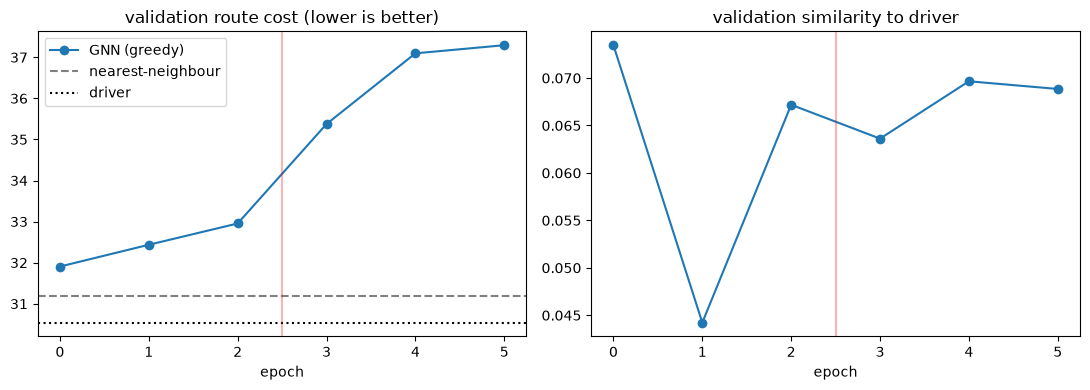

In [1]:
import json, pandas as pd, numpy as np, matplotlib.pyplot as plt
h = pd.DataFrame(json.load(open("../results/gnn_v2.history.json")))
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(h.epoch, h.val_policy, marker="o", label="GNN (greedy)")
ax[0].axhline(h.nn_ref.iloc[0], ls="--", c="gray", label="nearest-neighbour")
ax[0].axhline(h.driver_ref.iloc[0], ls=":", c="k", label="driver")
ax[0].axvline(2.5, c="red", alpha=.3)          # red line: imitation (left) -> REINFORCE (right)
ax[0].set_title("validation route cost (lower is better)"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot(h.epoch, h.val_sim, marker="o"); ax[1].axvline(2.5, c="red", alpha=.3)
ax[1].set_title("validation similarity to driver"); ax[1].set_xlabel("epoch")
plt.tight_layout(); plt.show()

In [2]:
df = pd.read_csv("../results/exp02_gnn.csv")
df.groupby("method")[["gap_vs_driver", "zone_sw", "sim_to_driver", "secs"]].mean().round(3).sort_values("gap_vs_driver")

,gap_vs_driver,zone_sw,sim_to_driver,secs
method,,,,
gnn_lns,-0.125,36.113,-0.009,11.508
lns,-0.124,36.887,-0.010,11.646
gnn_sa,-0.108,37.210,-0.011,11.774
sa,-0.104,38.161,-0.022,12.080
driver,0.000,22.081,1.000,0.000
nn,0.017,41.387,-0.031,0.001
gnn,0.088,43.968,-0.022,0.073


In [3]:
p = df.pivot(index="route", columns="method", values="gap_vs_driver")
def diff(a, b):
    d = (p[a] - p[b]).dropna() * 100
    return f"{a} - {b}: {d.mean():+.2f} pts  (95% CI ±{1.96*d.sem():.2f}, n={len(d)})"
for a_, b_ in [("gnn", "nn"), ("gnn_sa", "sa"), ("gnn_lns", "lns"), ("lns", "sa")]:
    print(diff(a_, b_))

gnn - nn: +7.06 pts  (95% CI ±1.58, n=62)
gnn_sa - sa: -0.36 pts  (95% CI ±0.63, n=62)
gnn_lns - lns: -0.04 pts  (95% CI ±0.47, n=62)
lns - sa: -1.98 pts  (95% CI ±0.50, n=62)


## Conclusions
- Imitation training gives a route cost close to, but not better than, nearest-neighbour; REINFORCE diverged (red line marks the switch).
- The GNN alone builds routes ~9% longer than the driver's, worse than nearest-neighbour (+7.1 ± 1.6 points).
- As a warm start it makes no measurable difference: gnn_sa − sa = −0.4 ± 0.6, gnn_lns − lns = −0.04 ± 0.5 points.
- LNS beats SA by ~2 points on this sample (−2.0 ± 0.5).
- Next: debug REINFORCE on small instances, or train on LNS solutions.